# CRISP-DM phase 2 : Data Understanding, D9 (Diabetes / Pima Indians, Mahgoub)

Responsable : Omar (diabète)

**À surveiller :** 768 patientes d'origine Pima, 8 prédicteurs physiologiques. ZÉROS MÉDICALEMENT IMPOSSIBLES : Glucose (5), BloodPressure (35), SkinThickness (227), Insulin (374), BMI (11) sont des valeurs manquantes masquées.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.datasets import load, REGISTRY

DS = 'D9'
df, target = load(DS)   # vérifie aussi la taille face au tableau 2 de l'article
REGISTRY[DS]['name'], df.shape

[D9] lignes=768 pos=268 neg=500 | article: lignes=768 pos=268 neg=500 -> OK


('Diabetes (KNN, Mahgoub) / Pima Indians', (768, 9))

## 1. Structure et dictionnaire des variables
Compléter le tableau dans le rapport : nom, signification médicale, type, unité.

In [2]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
pd.DataFrame({'dtype': df.dtypes, 'n_unique': df.nunique(), 'min': df.min(numeric_only=True), 'max': df.max(numeric_only=True)})

,dtype,n_unique,min,max
Pregnancies,int64,17,0.000,17.00
Glucose,int64,136,0.000,199.00
BloodPressure,int64,47,0.000,122.00
SkinThickness,int64,51,0.000,99.00
Insulin,int64,186,0.000,846.00
BMI,float64,248,0.000,67.10
DiabetesPedigreeFunction,float64,517,0.078,2.42
Age,int64,52,21.000,81.00
Outcome,int64,2,0.000,1.00


## 2. Variable cible

Outcome
0    500
1    268
Name: count, dtype: int64 
 Outcome
0    0.651
1    0.349
Name: count, dtype: float64


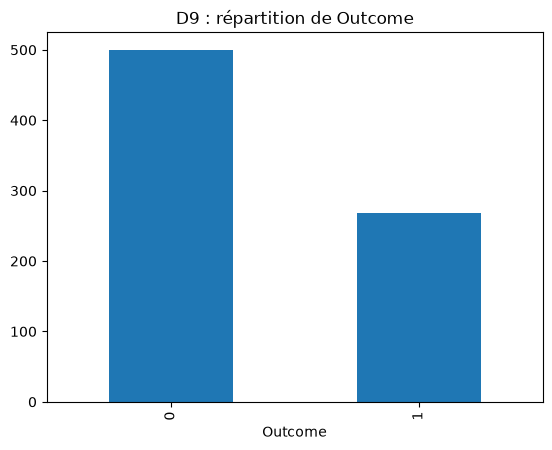

In [4]:
counts = df[target].value_counts().sort_index()
print(counts, '\n', (counts / len(df)).round(3))
counts.plot.bar(title=f'{DS} : répartition de {target}')
plt.show()

## 3. Valeurs manquantes (vraies et codées)

In [5]:
print('Valeurs nulles explicites :')
print(df.isna().sum()[df.isna().sum() > 0])

# Zéros médicalement impossibles (spécifique au diabète)
for c in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    if c in df:
        z = (df[c] == 0).sum()
        print(f'{c} = 0 : {z} ({z / len(df) * 100:.1f}%)')

Valeurs nulles explicites :
Series([], dtype: int64)
Glucose = 0 : 5 (0.7%)
BloodPressure = 0 : 35 (4.6%)
SkinThickness = 0 : 227 (29.6%)
Insulin = 0 : 374 (48.7%)
BMI = 0 : 11 (1.4%)


## 4. Doublons
L'article ne dit pas les avoir supprimés : on les **garde** pour reproduire ses résultats, puis on relance avec `--dedup` pour mesurer leur effet.

In [6]:
n_dup = df.duplicated().sum()
print(f'{n_dup} doublons sur {len(df)} lignes ({n_dup / len(df) * 100:.1f}%) -> {len(df) - n_dup} lignes uniques')
print('Répartition de la cible après déduplication :')
print(df.drop_duplicates()[target].value_counts())

0 doublons sur 768 lignes (0.0%) -> 768 lignes uniques
Répartition de la cible après déduplication :
Outcome
0    500
1    268
Name: count, dtype: int64


## 5. Statistiques descriptives et distributions

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


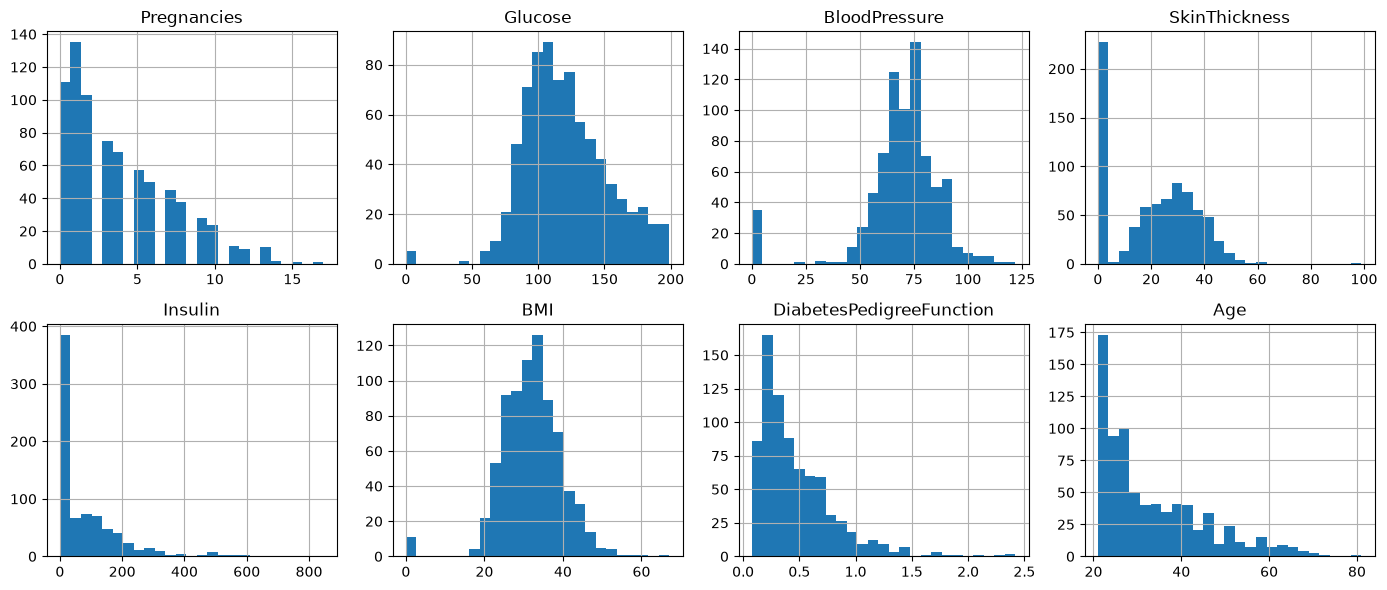

In [8]:
num = [c for c in df.columns if c != target and pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 5]
if num:
    df[num].hist(bins=25, figsize=(14, 3 * ((len(num) + 3) // 4)), layout=(-1, 4))
    plt.tight_layout()
    plt.show()
else:
    print('Pas de variables numériques continues (> 5 modalités)')

## 6. Valeurs aberrantes (méthode IQR)
Interpréter médicalement : erreur de saisie ou patient réellement extrême ?

In [9]:
if num:
    q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
    print(outliers[outliers > 0])
else:
    print('Aucune variable numérique continue')

BloodPressure               45
Insulin                     34
DiabetesPedigreeFunction    29
BMI                         19
Age                          9
Glucose                      5
Pregnancies                  4
SkinThickness                1
dtype: int64


## 7. Variables selon la classe

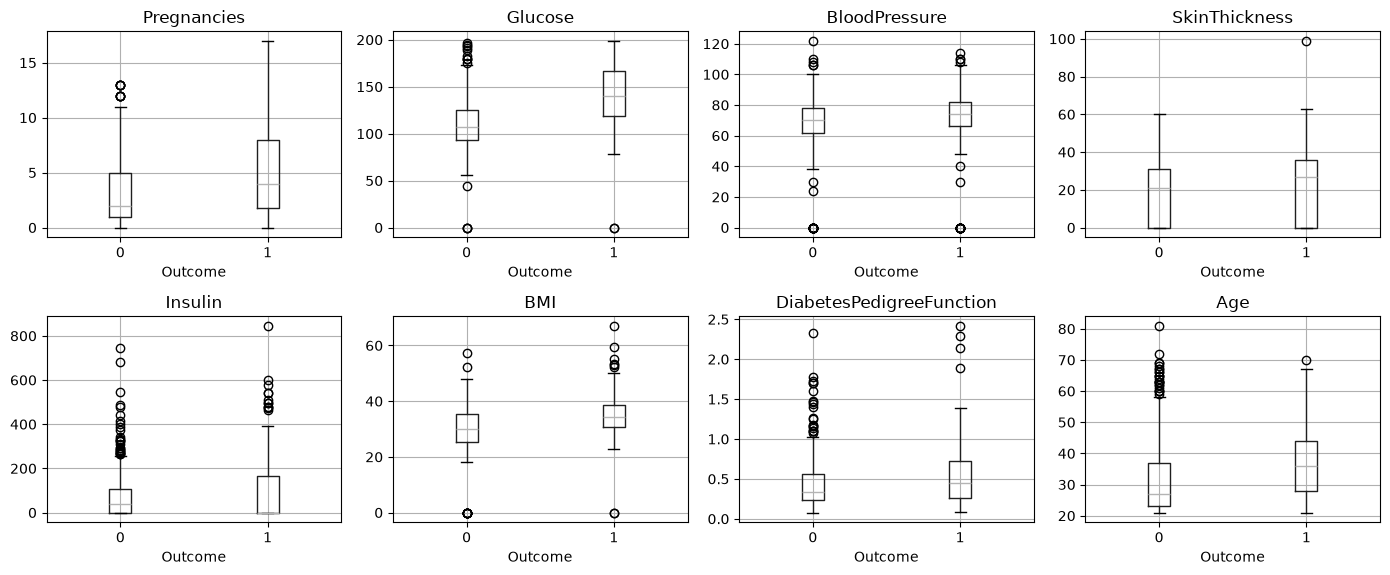

In [10]:
if num:
    fig, axes = plt.subplots((len(num) + 3) // 4, 4, figsize=(14, 3 * ((len(num) + 3) // 4)))
    for ax, c in zip(axes.flat, num):
        df.boxplot(column=c, by=target, ax=ax)
    plt.suptitle('')
    plt.tight_layout()
    plt.show()

In [11]:
cat = [c for c in df.columns if c != target and (df[c].nunique() <= 5 or not pd.api.types.is_numeric_dtype(df[c]))]
for c in cat[:10]:
    print(f'=== {c} vs {target} ===')
    print(pd.crosstab(df[c], df[target], normalize='index').round(2), '\n')

## 8. Corrélations

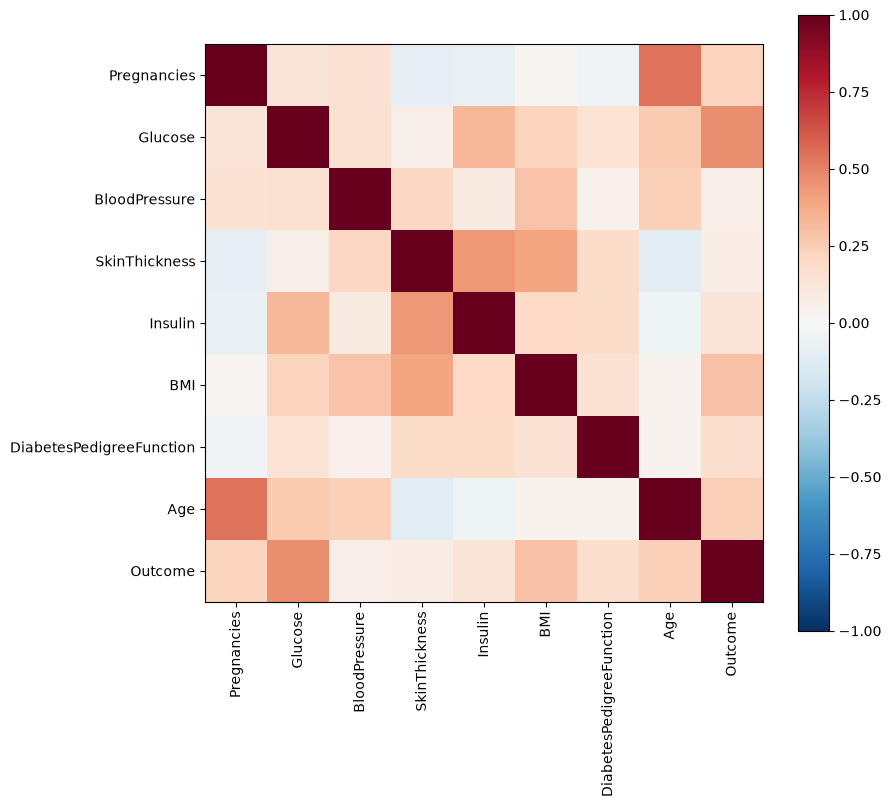

Corrélations avec la cible :
Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64


In [12]:
corr = df.select_dtypes('number').corr()
if len(corr) > 1:
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.columns)
    plt.colorbar(im)
    plt.show()
    if target in corr.columns:
        print('Corrélations avec la cible :')
        print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3))

## 9. Conclusions pour la préparation (phase 3)

- Variables à encoder : toutes les variables sont déjà numériques.
- Valeurs manquantes / codées à traiter : 5 variables contiennent des 0 physiologiquement impossibles (Glucose=0, BloodPressure=0, SkinThickness=0, Insulin=0, BMI=0). Ces zéros constituent des données manquantes non déclarées dans l'article.
- Doublons : 0 doublon dans ce dataset.
- Normalisation : StandardScaler dans le Pipeline GridSearchCV.